In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.layers import Dense, Input

In [5]:
# 1.1 Überblick
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print(x_train.shape, y_train.shape)   
print(x_test.shape, y_test.shape)     
print(x_train[0].shape)             
print(x_train[0])           

(60000, 28, 28) (60000,)
(10000, 28, 28) (10000,)
(28, 28)
[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251
   93  82  82  56  39   0   0   0   0   0]
 [  0

In [7]:
# 1.2 DataFrame erstellen basierend auf X_train
x_train_flat = x_train.reshape(60000, 784)
df = pd.DataFrame(x_train_flat)
df.head()        

,0,1,2,3,4,5,6,7,8,9,...,774,775,776,777,778,779,780,781,782,783
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


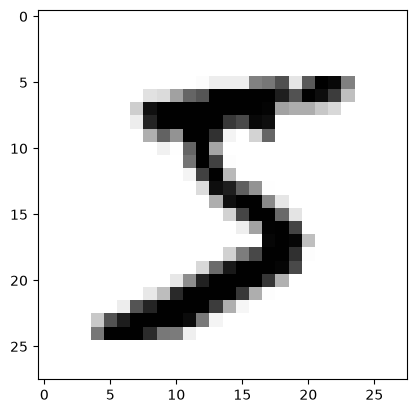

5


In [9]:
# 1.3 Ziffern an Position 0
plt.imshow(x_train[0], cmap="gray_r")
plt.show()

print(y_train[0]) # Kontrolle das 5 ausgegeben wird

In [17]:
# 1.4 
# 10 Knoten repsäsentieren die 10 verschiedenen Ziffern.

In [11]:
# 1.5 Modell definieren und kompilieren
model = Sequential()
model.add(Input(shape=(784,)))
model.add(Dense(64, activation="relu"))
model.add(Dense(10, activation="softmax"))

model.compile(
    optimizer="rmsprop",
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
# 1.6 Daten aufbereiten und trainieren
x_train_prepared = x_train.reshape(60000, 784)
x_test_prepared = x_test.reshape(10000, 784)

y_train_onehot = to_categorical(y_train, 10)
y_test_onehot = to_categorical(y_test, 10)

model.fit(x_train_prepared, y_train_onehot, epochs=50, batch_size=128)

Epoch 1/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.8092 - loss: 3.7308
Epoch 2/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.8992 - loss: 0.5242
Epoch 3/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.9269 - loss: 0.3693
Epoch 4/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.9376 - loss: 0.3000
Epoch 5/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.9463 - loss: 0.2574
Epoch 6/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.9522 - loss: 0.2250
Epoch 7/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.9559 - loss: 0.2011
Epoch 8/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.9592 - loss: 0.1882
Epoch 9/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.9620 - loss: 0.1716
Epoch 10/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.9646 - loss: 0.1704
Epoch 11/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 12s 18ms/step - accuracy: 0.9647 - loss: 0.1594
Epoch 12/50
469/469 ━━━━━━━━━━━━━━━━━

In [15]:
# 1.7 Validierung mit den Testdaten
model.evaluate(x_test_prepared, y_test_onehot)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9612 - loss: 0.6524


[0.6524384617805481, 0.9611999988555908]

In [17]:
# MINST2
def create_model():
    model = Sequential()
    model.add(Input(shape=(784,)))
    model.add(Dense(64, activation="relu"))
    model.add(Dense(10, activation="softmax"))
    model.compile(
        optimizer="rmsprop",
        loss="categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

Epoch 1/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.8226 - loss: 4.1345
Epoch 2/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9013 - loss: 0.5409
Epoch 3/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.9270 - loss: 0.3767
Epoch 4/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.9390 - loss: 0.3046
Epoch 5/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9466 - loss: 0.2576
Epoch 6/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.9526 - loss: 0.2255
Epoch 7/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9563 - loss: 0.2058
Epoch 8/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9592 - loss: 0.1870
Epoch 9/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.9624 - loss: 0.1768
Epoch 10/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.9648 - loss: 0.1674
Epoch 11/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9667 - loss: 0.1511
Epoch 12/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms

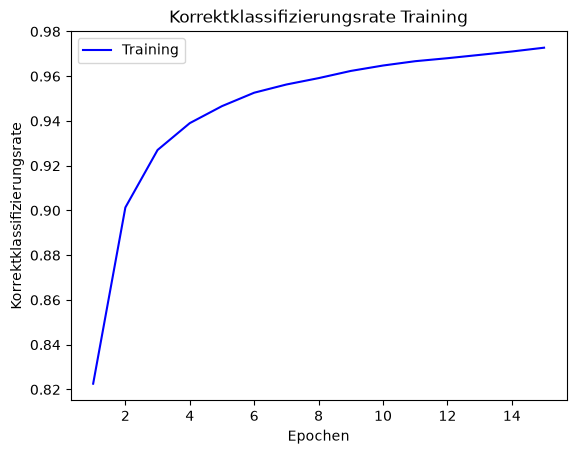

In [21]:
# 18.2.1 Training mit 15 Epochen und Plot der Accuracy
model = create_model()
model_history = model.fit(x_train_prepared, y_train_onehot, epochs=15, batch_size=128)

acc = model_history.history["accuracy"]
epochs = range(1, len(acc) + 1)

plt.plot(epochs, acc, 'b', label="Training")
plt.title("Korrektklassifizierungsrate Training")
plt.xlabel("Epochen")
plt.ylabel("Korrektklassifizierungsrate")
plt.legend()
plt.show()

Epoch 1/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 23s 21ms/step - accuracy: 0.8267 - loss: 2.6278 - val_accuracy: 0.9002 - val_loss: 0.5776
Epoch 2/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 18s 19ms/step - accuracy: 0.9132 - loss: 0.4685 - val_accuracy: 0.9139 - val_loss: 0.5099
Epoch 3/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 18s 16ms/step - accuracy: 0.9288 - loss: 0.3793 - val_accuracy: 0.9292 - val_loss: 0.4175
Epoch 4/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 13s 13ms/step - accuracy: 0.9383 - loss: 0.3346 - val_accuracy: 0.9298 - val_loss: 0.4680
Epoch 5/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 19s 20ms/step - accuracy: 0.9433 - loss: 0.2957 - val_accuracy: 0.9366 - val_loss: 0.4097
Epoch 6/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 31s 30ms/step - accuracy: 0.9488 - loss: 0.2749 - val_accuracy: 0.9430 - val_loss: 0.4038
Epoch 7/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 17s 18ms/step - accuracy: 0.9523 - loss: 0.2622 - val_accuracy: 0.9443 - val_loss: 0.4307
Epoch 8/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 13s 13ms/step - accuracy: 0.9536 - loss: 0.2437 - 

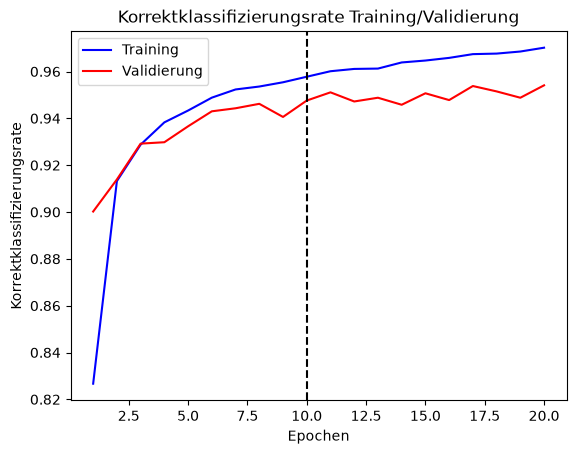

In [23]:
# 18.2.2 Training mit Validierungsdaten und Plot
model = create_model()
model_history = model.fit(
    x_train_prepared,
    y_train_onehot,
    epochs=20,
    batch_size=64,
    validation_data=(x_test_prepared, y_test_onehot),
)

print(model_history.history.keys())   # zeigt: loss, accuracy, val_loss, val_accuracy

acc = model_history.history["accuracy"]
val_acc = model_history.history["val_accuracy"]
epochs = range(1, len(acc) + 1)

plt.plot(epochs, acc, 'b', label="Training")
plt.plot(epochs, val_acc, 'r', label="Validierung")
plt.axvline(x=10, color="black", linestyle="--")
plt.title("Korrektklassifizierungsrate Training/Validierung")
plt.xlabel("Epochen")
plt.ylabel("Korrektklassifizierungsrate")
plt.legend()
plt.show()